# Figure 5: Hit Analysis

Examines validated hits from the PhenoCompass-driven phenotypic screen, including their experimental scores, kinase binding profiles, and chemical similarity to known compounds.

This notebook generates:
1. Combined summary heatmap of hit status, CP/FOXO3A scores, and kinase binding
2. Kinase-control summary heatmap
3. Max Tanimoto similarity heatmap (kinase-active hits vs. anchors, JUMP, and PI3K drugs)
4. Pairwise Tanimoto similarity heatmap among kinase-active hits
5. Per-hit molecule grid images with most similar PI3K drug and JUMP compound

## Prerequisites

Run `Fig5_cellpainting_foxo3a_validation.ipynb` before this notebook — it produces `data/cellpainting_validation/cp_phenosimilarity_scores.csv`, which is read below.

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import seaborn as sns
import img2pdf
import cairosvg


from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import MolsToGridImage, rdMolDraw2D

from phenocompass.data.featurization import mol_to_mf, canonicalize_smiles, load_jump_canonical_map
from phenocompass.evaluation.metrics import compute_pairwise_tanimoto_similarity
from phenocompass.data.dataset import FastH5DatasetJUMP

import phenocompass
_nb_dir = os.path.abspath(os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
sys.path.insert(0, _nb_dir)
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

%matplotlib inline

# --- Morgan fingerprint generator ---
fpgen = AllChem.GetMorganGenerator(radius=3, fpSize=2048)
mf_featurizer = fpgen.GetCountFingerprint

# --- Output directories ---
BASE_DIR = str(REPO_ROOT)
setup_publication_style(BASE_DIR)

DATA_DIR = os.path.join(BASE_DIR, "data", "hits")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "hits")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = True

# --- Tautomer canonicalization toggle ---
# When True (default), Tanimoto-based analyses use tautomer-canonicalized SMILES.
# Set to False to reproduce the originally published manuscript figures.
USE_TAUTOMER_CANONICALIZATION = True
JUMP_CANON_CACHE_PATH = os.path.join(
    FINAL_DATA_DIR, "compound_annotations/jump_canonicalized_smiles.parquet"
)

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")
if USE_TAUTOMER_CANONICALIZATION:
    print("USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)")
else:
    print("USE_TAUTOMER_CANONICALIZATION = False (original SMILES)")


No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/
USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)


## 2. Data Loading

### 2.2 Load and process binding data

In [2]:
# Load CP validation data
cp_phenosim_df = pd.read_csv(os.path.join(BASE_DIR, "data/cellpainting_validation/cp_phenosimilarity_scores.csv"))
compound_id_cp_score_mapper = cp_phenosim_df.set_index("Metadata_COMPOUND_ID")["phenosimilarity_score"].to_dict()

# Load FOXO3A validation data
foxo3a_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "validation/foxo3a_results.tsv"), sep="\t")
compound_id_foxo3a_score_mapper = foxo3a_df.set_index("COMPOUND_ID")["mean_clip_5"].to_dict()

# Load binding assay data
binding_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "validation/avg-rbio.csv"))
binding_df["cp_score"] = binding_df["COMPOUND_ID"].map(compound_id_cp_score_mapper)
binding_df["foxo3a_score"] = binding_df["COMPOUND_ID"].map(compound_id_foxo3a_score_mapper)

# Rename column
binding_df.columns = [n.replace("MTOR", "mTOR") for n in binding_df.columns]

# Control compounds
control_binding_df = binding_df[binding_df["COMPOUND_ID"].str.contains("_con")]

# Keep only non-control compounds
binding_df = binding_df[~binding_df["COMPOUND_ID"].str.contains("_con")]
binding_df.index = binding_df["COMPOUND_ID"].values

# Sort by FOXO3A z-score
binding_df = binding_df.sort_values("foxo3a_score", ascending=False).reset_index(drop=True)

# Binarize kinase hits
binding_df["is_kinase_hit"] = (
    (binding_df[["PI3Ka_avg", "PI3Kb_avg", "PI3Kd_avg", "PI3Kg_avg", "AKT_avg", "mTOR_avg"]] > 50).sum(1) > 0
).astype(int)

hits_data_df = binding_df.copy()

### 2.3 Load JUMP dataset and compute fingerprints

In [3]:
# --- Load JUMP dataset (loaded once, used in multiple figures) ---
h5_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_dino_tvn.h5")
index_predetermined_file = os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_cluster_splits.pkl")

dataset = FastH5DatasetJUMP(
    h5_path,
    avg_morph_feat=True,
    index_predetermined_file=index_predetermined_file,
    ohe_batch=False,
    struct_ipt="fixed",
    fixed_struct_data=os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet")
)

# JUMP SMILES used for fingerprinting: canonicalized if toggle on, else original.
# The original dataset.ids stays as-is for use as the row/column labels in
# Tanimoto matrices and downstream lookup.
if USE_TAUTOMER_CANONICALIZATION:
    smiles_to_canon = load_jump_canonical_map(JUMP_CANON_CACHE_PATH)
    jump_smiles_for_fp = [smiles_to_canon.get(s, s) for s in dataset.ids]
else:
    jump_smiles_for_fp = list(dataset.ids)

jump_mf = [mol_to_mf(s, mf_featurizer) for s in jump_smiles_for_fp]
print(f"JUMP dataset: {len(dataset.ids)} compounds")


[21:43:31] Unusual charge on atom 3 number of radical electrons set to zero


JUMP dataset: 108836 compounds


### 2.4 Load anchor sets and compound fingerprints

In [4]:
# --- Load anchor compounds ---
# Load consolidated anchor file for mTOR/PI3K anchors (cluster_idx == 3)
anchor_compounds_df = pd.read_csv(
    os.path.join(FINAL_DATA_DIR, "compound_annotations/anchor_compounds.tsv"),
    sep="\t"
)
mtor_pi3k_anchors = anchor_compounds_df[anchor_compounds_df["cluster_moa"] == "PI3K/mTOR"]["canonical_SMILES"].values

if USE_TAUTOMER_CANONICALIZATION:
    mtor_pi3k_anchors_for_fp = [canonicalize_smiles(s) for s in mtor_pi3k_anchors]
else:
    mtor_pi3k_anchors_for_fp = list(mtor_pi3k_anchors)
mtor_pi3k_anchors_mf = [mol_to_mf(s, mf_featurizer) for s in mtor_pi3k_anchors_for_fp]

# Load PI3K drugs from anchor_sets (these are clinical-stage PI3K inhibitors, not JUMP compounds)
pi3k_drugs_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "chembl_drugs/chembl_drugs.pi3k.tsv"), sep="\t")
pi3k_drugs = pi3k_drugs_df["SMILES"].values

if USE_TAUTOMER_CANONICALIZATION:
    pi3k_drugs_for_fp = [canonicalize_smiles(s) for s in pi3k_drugs]
else:
    pi3k_drugs_for_fp = list(pi3k_drugs)
pi3k_drugs_mf = [mol_to_mf(s, mf_featurizer) for s in pi3k_drugs_for_fp]

# Hit compound fingerprints (all hits, for Figures 1-4)
top_hit_compounds, top_hit_smiles = hits_data_df[["COMPOUND_ID", "canonical_SMILES"]].values.T
if USE_TAUTOMER_CANONICALIZATION:
    top_hit_smiles_for_fp = [canonicalize_smiles(s) for s in top_hit_smiles]
else:
    top_hit_smiles_for_fp = list(top_hit_smiles)
top_hit_compounds_mf = [mol_to_mf(s, mf_featurizer) for s in top_hit_smiles_for_fp]

print(f"PI3K drugs: {len(pi3k_drugs)}, mTOR/PI3K anchors: {len(mtor_pi3k_anchors)}, Hits")


[21:43:33] Tautomer enumeration stopped at 346 tautomers: max transforms reached


PI3K drugs: 55, mTOR/PI3K anchors: 13, Hits


## 3. Compute Tanimoto Similarities

### 3.1 Tanimoto similarity matrices (all hits)

In [5]:
anchors_cache = os.path.join(DATA_DIR, "tanimoto_sim_hits_vs_anchors.csv")
jump_cache = os.path.join(DATA_DIR, "tanimoto_sim_hits_vs_jump.csv")
pi3k_cache = os.path.join(DATA_DIR, "tanimoto_sim_hits_vs_pi3k_drugs.csv")
pairwise_cache = os.path.join(DATA_DIR, "tanimoto_sim_hits_pairwise.csv")

if all(os.path.exists(p) for p in [anchors_cache, jump_cache, pi3k_cache, pairwise_cache]) and not FORCE_RECOMPUTE:
    tanimoto_sim_mtor_pi3k_anchors_df = pd.read_csv(anchors_cache, index_col=0)
    tanimoto_sim_jump_df = pd.read_csv(jump_cache, index_col=0)
    tanimoto_sim_pi3k_drugs_df = pd.read_csv(pi3k_cache, index_col=0)
    top_hits_pairwise_df = pd.read_csv(pairwise_cache, index_col=0)
    print("Loaded cached Tanimoto similarity matrices.")
else:
    # Hits vs. mTOR/PI3K anchors
    tanimoto_sim_mtor_pi3k_anchors_df = pd.DataFrame(
        compute_pairwise_tanimoto_similarity(top_hit_compounds_mf, mtor_pi3k_anchors_mf),
        index=top_hit_compounds, columns=mtor_pi3k_anchors
    )

    # Hits vs. JUMP compounds
    tanimoto_sim_jump_df = pd.DataFrame(
        compute_pairwise_tanimoto_similarity(top_hit_compounds_mf, jump_mf),
        index=top_hit_compounds, columns=dataset.ids
    )

    # Hits vs. PI3K drugs
    tanimoto_sim_pi3k_drugs_df = pd.DataFrame(
        compute_pairwise_tanimoto_similarity(top_hit_compounds_mf, pi3k_drugs_mf),
        index=top_hit_compounds, columns=pi3k_drugs
    )

    # Pairwise similarity between hits
    top_hits_pairwise_df = pd.DataFrame(
        compute_pairwise_tanimoto_similarity(top_hit_compounds_mf, top_hit_compounds_mf),
        index=top_hit_compounds, columns=top_hit_compounds
    )

    print("Computed Tanimoto similarity matrices.")

Computed Tanimoto similarity matrices.


### 3.3 Assemble plot dataframe

In [6]:
plot_df_cache = os.path.join(DATA_DIR, "hits_plot_df.csv")
hits_data_cache = os.path.join(DATA_DIR, "hits_data_processed.csv")

if os.path.exists(plot_df_cache) and not FORCE_RECOMPUTE:
    plot_df = pd.read_csv(plot_df_cache, index_col=0)
    if os.path.exists(hits_data_cache):
        hits_data_df = pd.read_csv(hits_data_cache)
    print("Loaded cached plot_df and hits_data_df")
else:
    # Add summary columns to hits_data_df
    hits_data_df["max_ts_mtor_pi3k_anchors"] = tanimoto_sim_mtor_pi3k_anchors_df.max(1).values
    hits_data_df["max_ts_jump"] = tanimoto_sim_jump_df.max(1).values
    hits_data_df["max_ts_pi3k_drugs"] = tanimoto_sim_pi3k_drugs_df.max(1).values

    # Prepare plot dataframe
    plot_df = hits_data_df.copy()
    plot_df.sort_values("foxo3a_score", ascending=False, inplace=True)
    plot_df.index = plot_df["COMPOUND_ID"].values
    plot_df["is_cp_hit"] = plot_df["is_cp_hit"].astype(int)
    plot_df["is_foxo3a_hit"] = plot_df["is_foxo3a_hit"].astype(int)
    print("Assembled plot_df from computed data")

Assembled plot_df from computed data


## 4. Save Intermediate Data

In [7]:
saved = []
save_pairs = [
    (hits_data_df, "hits_data_processed.csv", False),
    (plot_df, "hits_plot_df.csv", True),
    (tanimoto_sim_mtor_pi3k_anchors_df, "tanimoto_sim_hits_vs_anchors.csv", True),
    (tanimoto_sim_pi3k_drugs_df, "tanimoto_sim_hits_vs_pi3k_drugs.csv", True),
    (tanimoto_sim_jump_df, "tanimoto_sim_hits_vs_jump.csv", True),
    (top_hits_pairwise_df, "tanimoto_sim_hits_pairwise.csv", True),
]

for df, fname, use_index in save_pairs:
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path) or FORCE_RECOMPUTE:
        if use_index:
            df.to_csv(path)
        else:
            df.to_csv(path, index=False)
        saved.append(fname)

if saved:
    print(f"Saved {len(saved)} files")
else:
    print("All data files already exist, skipping saves.")

Saved 6 files


## 5. Generate Figures

### Figure 1: Combined Summary Heatmap

Multi-panel heatmap showing hit status, CP/FOXO3A scores, and kinase binding percentages.

Saved figure


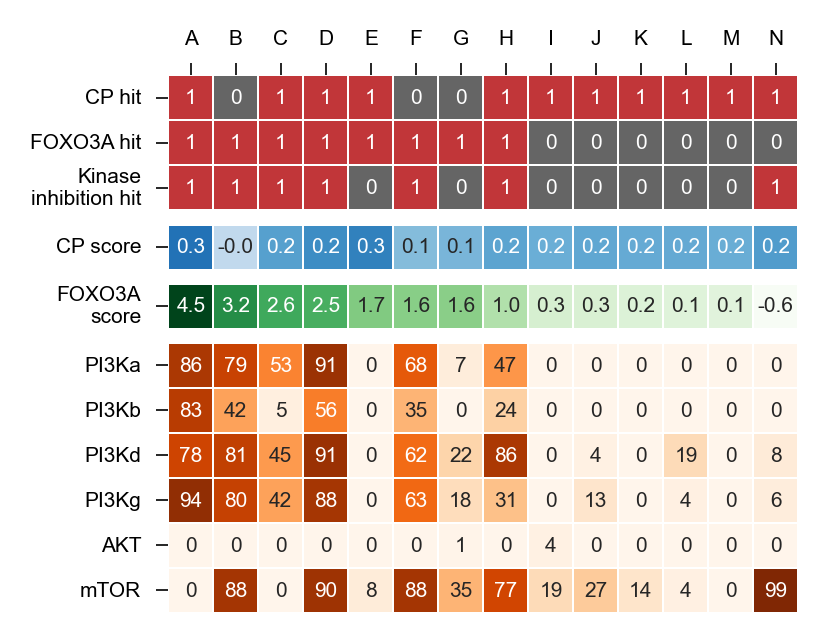

Figure 1 done.


In [8]:
abc = "ABCDEFGHIJKLMNOP"
binding_columns = [n for n in hits_data_df.columns if "_avg" in n]
n_hits = len(plot_df)
n_binding = len(binding_columns)
cell_size = 0.15
gap = 0.015
left = 0.25
top_start = 0.92

fig = plt.figure(figsize=(n_hits * cell_size + 1.2, (3 + 1 + 1 + n_binding) * cell_size + 1.5))
gs = GridSpec(4, 1, figure=fig, wspace=0.1, hspace=0,
              height_ratios=[3, 1, 1, n_binding])

# ax1: Hit status (3 rows)
ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(plot_df[["is_cp_hit", "is_foxo3a_hit", "is_kinase_hit"]].T,
            square=True, annot=True, annot_kws={"size": 5}, edgecolor="w", linewidths=0.1,
            cbar=False, cmap="RdGy_r", vmin=-0.2, vmax=1.2, ax=ax1)
ax1.set_xticks(np.arange(n_hits) + 0.5)
ax1.set_xticklabels([abc[i] for i in range(n_hits)], rotation=0)
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.set_yticks([0.5, 1.5, 2.5])
ax1.set_yticklabels(["CP hit", "FOXO3A hit", "Kinase\ninhibition hit"])
ax1.tick_params(axis='x', which='both', bottom=False, top=True, labelbottom=False, labeltop=True)

# ax2: CP score (1 row)
ax2 = fig.add_subplot(gs[1, 0])
sns.heatmap(plot_df[["cp_score"]].T,
            square=True, annot=True, annot_kws={"size": 5}, edgecolor="w", linewidths=0.1,
            cbar=False, cmap="Blues", fmt=".1f", ax=ax2, vmin=-0.2, vmax=0.5)
ax2.set_xticks(np.arange(n_hits) + 0.5)
ax2.set_xticklabels([])
ax2.set_yticks([0.5])
ax2.set_yticklabels(["CP score"], rotation=0)
ax2.xaxis.set_visible(False)

# ax3: FOXO3A score (1 row)
ax3 = fig.add_subplot(gs[2, 0])
sns.heatmap(plot_df[["foxo3a_score"]].T,
            square=True, annot=True, annot_kws={"size": 5}, edgecolor="w", linewidths=0.1,
            cbar=False, cmap="Greens", fmt=".1f", ax=ax3)
ax3.set_xticks(np.arange(n_hits) + 0.5)
ax3.set_xticklabels([])
ax3.set_yticks([0.5])
ax3.set_yticklabels(["FOXO3A\nscore"], rotation=0)
ax3.xaxis.set_visible(False)

# ax4: Binding (n_binding rows)
ax4 = fig.add_subplot(gs[3, 0])
sns.heatmap(plot_df[binding_columns].clip(0, 100).T,
            square=True, annot=True, fmt=".0f", annot_kws={"size": 5}, cmap="Oranges", edgecolor="w", linewidths=0.1,
            cbar=False, vmin=0, vmax=100, ax=ax4)
ax4.set_xticks([])
ax4.set_xticklabels([])
ax4.set_yticks(np.arange(len(binding_columns)) + 0.5)
ax4.set_yticklabels([n.split("_")[0] for n in binding_columns])
ax4.tick_params(axis='x', which='both', labelbottom=False, bottom=False, top=False, labeltop=False)

# Manually reposition axes for uniform gaps
fig_width, fig_height = fig.get_size_inches()
cell_width = cell_size / fig_width
cell_height = cell_size / fig_height
heatmap_width = n_hits * cell_width

row_counts = [3, 1, 1, n_binding]
axes_list = [ax1, ax2, ax3, ax4]
top = top_start
for ax, n_rows in zip(axes_list, row_counts):
    height = n_rows * cell_height
    bottom = top - height
    ax.set_position([left, bottom, heatmap_width, height])
    top = bottom - gap

fig1_path = os.path.join(FIGURE_DIR, "Fig5_val_summary_heatmap.combined.pdf")
save_figure(fig1_path, FORCE_RECOMPUTE)
plt.show()
print("Figure 1 done.")

Saved figure


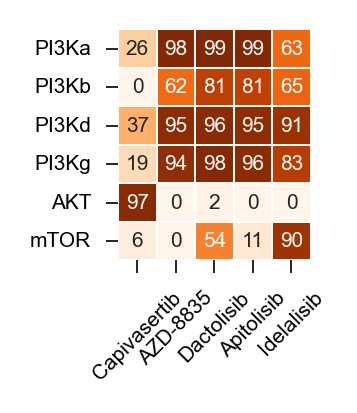

Figure 1 (kinase controls) done.
Saved figure data


In [9]:
plt.figure(figsize=(1,1))
ax = sns.heatmap(control_binding_df[binding_columns].clip(0, 100).T,
            square=True, annot=True, fmt=".0f", annot_kws={"size": 5}, cmap="Oranges", edgecolor="w", linewidths=0.1,
            cbar=False, vmin=0, vmax=100)

control_drug_names = [n.split("(")[1].strip(")") for n in control_binding_df["COMPOUND_ID"].values]
control_drug_name_mapper = {"AZD-5365": "Capivasertib",
                            "AZ-8835": "AZD-8835",
                            "BEZ-235": "Dactolisib",
                            "GDC-0980": "Apitolisib",
                            "Idelisib": "Idelalisib"}

ax.set_xticklabels([control_drug_name_mapper[n] for n in control_drug_names],
                    rotation=45)
ax.set_yticks(np.arange(len(binding_columns)) + 0.5)
ax.set_yticklabels([n.split("_")[0] for n in binding_columns])

fig1_path = os.path.join(FIGURE_DIR, "FigS11_val_summary_heatmap.kinase_controls.pdf")
save_figure(fig1_path, FORCE_RECOMPUTE)
plt.show()
print("Figure 1 (kinase controls) done.")

# Save kinase controls data
kinase_controls_data = control_binding_df[["COMPOUND_ID"] + binding_columns].copy()
kinase_controls_data["drug_name"] = [control_drug_name_mapper[n.split("(")[1].strip(")")] for n in control_binding_df["COMPOUND_ID"].values]
fig_data_path = os.path.join(FIGURE_DIR, "FigS11_val_summary_heatmap_kinase_controls_data.tsv")
save_figure_data(kinase_controls_data, fig_data_path, FORCE_RECOMPUTE)

plt.show()

### Figure 2: Max Tanimoto Similarity Heatmap

Max Tanimoto similarity of kinase-active hits to PI3K/mTOR anchors, JUMP, and clinical PI3K inhibitors.

Saved figure


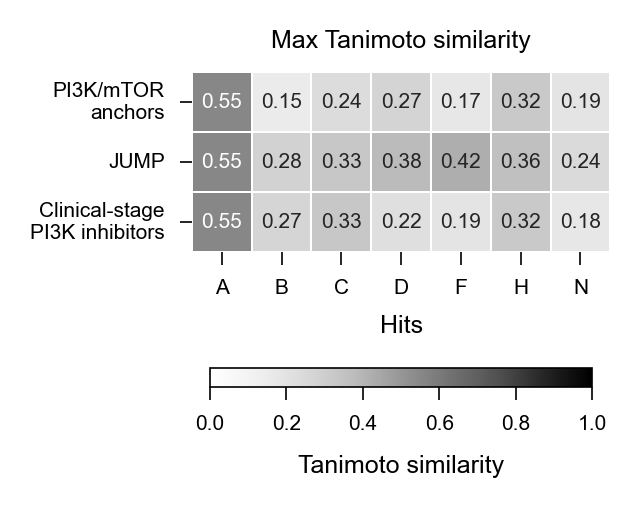

Figure 2 done.


In [10]:
abc = "ABCDEFGHIJKLMNOP"
columns2keep = ["max_ts_mtor_pi3k_anchors", "max_ts_jump", "max_ts_pi3k_drugs"]

hit_plot_df = plot_df.copy()
hit_plot_df.index = ["{}".format(abc[i]) for i, n in enumerate(hit_plot_df.index)]
idx2keep = np.where(
    (hit_plot_df[["PI3Ka_avg", "PI3Kb_avg", "PI3Kd_avg", "PI3Kg_avg", "AKT_avg", "mTOR_avg"]] > 50).sum(1)
)[0]
hit_plot_df = hit_plot_df.iloc[idx2keep, :]

fig, ax = plt.subplots(figsize=(1.8, 1.8))
sns.heatmap(
    hit_plot_df[columns2keep].T,
    square=True, annot=True, fmt=".2f", annot_kws={"size": 5}, cmap="Greys",
    edgecolor="w", linewidths=0.1, cbar=False, vmin=0, vmax=1, ax=ax
)

cbar = fig.colorbar(
    mpl.cm.ScalarMappable(cmap="Greys", norm=mpl.colors.Normalize(vmin=0, vmax=1)),
    ax=ax, fraction=0.046, pad=0.28, orientation="horizontal"
)
cbar.ax.tick_params(labelsize=5)
cbar.set_label("Tanimoto similarity", labelpad=5)

ax.set_xlabel("Hits")
ax.set_yticks([0.5, 1.5, 2.5])
ax.set_yticklabels(["PI3K/mTOR\nanchors", "JUMP", "Clinical-stage\nPI3K inhibitors"])
ax.set_title("Max Tanimoto similarity")

fig2_path = os.path.join(FIGURE_DIR, "FigS12_val_summary_heatmap.max_tanimoto.pdf")
save_figure(fig2_path, FORCE_RECOMPUTE)
plt.show()
print("Figure 2 done.")

### Figure 3: Pairwise Tanimoto Similarity Heatmap

Pairwise Tanimoto similarity between kinase-active hits.

Saved figure


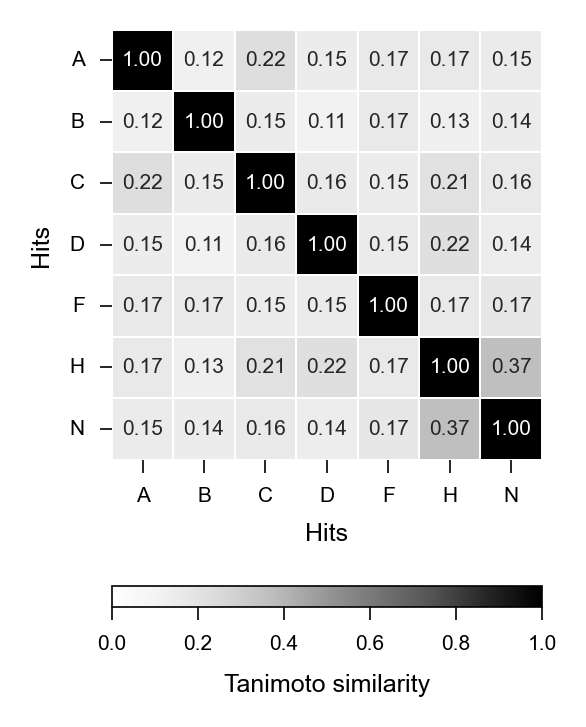

Figure 3 done.


In [11]:
abc = "ABCDEFGHIJKLMNOP"
idx2keep = np.where(
    (plot_df[["PI3Ka_avg", "PI3Kb_avg", "PI3Kd_avg", "PI3Kg_avg", "AKT_avg", "mTOR_avg"]] > 50).sum(1)
)[0]

fig, ax = plt.subplots(figsize=(2.5, 2.5))
hit_pairwise_plot_df = top_hits_pairwise_df.copy()
hit_pairwise_plot_df.index = ["{}".format(abc[i]) for i, n in enumerate(hit_pairwise_plot_df.index)]
hit_pairwise_plot_df.columns = ["{}".format(abc[i]) for i, n in enumerate(hit_pairwise_plot_df.columns)]
hit_pairwise_plot_df = hit_pairwise_plot_df.iloc[idx2keep, idx2keep]

sns.heatmap(
    hit_pairwise_plot_df,
    square=True, annot=True, fmt=".2f", annot_kws={"size": 5},
    cmap="Greys", edgecolor="w", linewidths=0.1,
    cbar=False, vmin=0, vmax=1, ax=ax
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va='center')

divider = make_axes_locatable(ax)
cax = divider.append_axes('bottom', size='5%', pad=0.42)
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(cmap="Greys", norm=mpl.colors.Normalize(vmin=0, vmax=1)),
    cax=cax, orientation="horizontal", pad=0.56
)
cbar.ax.tick_params(labelsize=5)
cbar.set_label("Tanimoto similarity", labelpad=5)

ax.set_xlabel("Hits")
ax.set_ylabel("Hits")

fig3_path = os.path.join(FIGURE_DIR, "FigS12_val_summary_heatmap.pairwise_tanimoto.pdf")
save_figure(fig3_path, FORCE_RECOMPUTE)
plt.show()
print("Figure 3 done.")

### Figure 4: Molecule Grid Images

Per-hit molecule grids showing the hit compound alongside its most similar PI3K drug and most similar JUMP compound.

In [12]:
# Prepare molecule matrices for visualization

# Most similar PI3K drugs
top_pi3k_indices = np.argmax(tanimoto_sim_pi3k_drugs_df.values, axis=1)

pi3k_MolsMatrix = [
    [Chem.MolFromSmiles(top_hit_smiles[i]), Chem.MolFromSmiles(pi3k_drugs[top_pi3k_indices[i]])]
    for i in range(len(top_hit_compounds))
]
pi3k_LegendsMatrix = [
    ["({}) {}".format(i + 1, top_hit_compounds[i]),
     "Most similar (TS={:.2f})".format(tanimoto_sim_pi3k_drugs_df.iloc[i, top_pi3k_indices[i]])]
    for i in range(len(top_hit_compounds))
]

# Most similar JUMP compounds (top 3)
top_3_jump_indices = np.argsort(tanimoto_sim_jump_df.values, axis=1)[:, -3:][:, ::-1]

jump_MolsMatrix = [
    [Chem.MolFromSmiles(top_hit_smiles[i])] +
    [Chem.MolFromSmiles(dataset.ids[top_3_jump_indices[i, j]]) for j in range(3)]
    for i in range(len(top_hit_compounds))
]
jump_LegendsMatrix = [
    ["({}) {}".format(i + 1, top_hit_compounds[i]),
     "Most similar (TS={:.2f})".format(tanimoto_sim_jump_df.iloc[i, top_3_jump_indices[i, 0]]),
     "2nd most similar (TS={:.2f})".format(tanimoto_sim_jump_df.iloc[i, top_3_jump_indices[i, 1]]),
     "3rd most similar (TS={:.2f})".format(tanimoto_sim_jump_df.iloc[i, top_3_jump_indices[i, 2]])]
    for i in range(len(top_hit_compounds))
]

print("Molecule matrices prepared.")

Molecule matrices prepared.


In [13]:
# Generate and save molecule grids as vector PDFs (rendered via SVG, no SVG/PNG kept)
dopts = rdMolDraw2D.MolDrawOptions()
dopts.minFontSize = 36
dopts.padX = 5

alphabet = "abcdefghijklmnopqrstuvwxyz"

panelW, panelH = 650, 250
n_panels = 3

for i in range(len(top_hit_compounds)):
    MolsMatrix = [
        pi3k_MolsMatrix[i][0],     # hit compound
        pi3k_MolsMatrix[i][1],     # most similar PI3K drug
        jump_MolsMatrix[i][1]      # most similar JUMP compound
    ]

    pdf_path = os.path.join(FIGURE_DIR, "Fig5_hit_summary.hit_{}.pdf".format(alphabet[i].upper()))

    if FORCE_RECOMPUTE or not os.path.exists(pdf_path):
        drawer = rdMolDraw2D.MolDraw2DSVG(panelW * n_panels, panelH, panelW, panelH)
        drawer.SetDrawOptions(dopts)
        drawer.DrawMolecules(MolsMatrix)
        drawer.FinishDrawing()
        svg_bytes = drawer.GetDrawingText().encode("utf-8")
        cairosvg.svg2pdf(bytestring=svg_bytes, write_to=pdf_path)

print("Molecule grid PDFs done.")

Molecule grid PDFs done.


In [14]:
# Verify the vector PDF for each hit was written
for i in range(len(top_hit_compounds)):
    pdf_path = os.path.join(FIGURE_DIR, "Fig5_hit_summary.hit_{}.pdf".format(alphabet[i].upper()))
    status = "OK" if os.path.exists(pdf_path) else "MISSING"
    print(f"  [{status}]")

  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]
  [OK]


In [15]:
# Save figure source data for manuscript reproducibility
# Consolidated hit summary data in long format
abc = "ABCDEFGHIJKLMNOP"
hit_labels = [abc[i] for i in range(len(plot_df))]

# Base hit metadata
hit_summary_data = plot_df.copy()
hit_summary_data["hit_label"] = hit_labels

# Add pairwise Tanimoto similarities in long format
pairwise_records = []
for i, row_compound in enumerate(plot_df.index):
    for j, col_compound in enumerate(plot_df.index):
        pairwise_records.append({
            "pairwise_hit_row": hit_labels[i],
            "pairwise_hit_col": hit_labels[j],
            "pairwise_tanimoto": top_hits_pairwise_df.loc[row_compound, col_compound]
        })

pairwise_df = pd.DataFrame(pairwise_records)

# Save hit metadata (one row per hit)
fig_data_path = os.path.join(FIGURE_DIR, "Fig5_S12_hit_summary_data.tsv")
save_figure_data(hit_summary_data, fig_data_path, FORCE_RECOMPUTE)

# Save pairwise Tanimoto data
fig_data_path = os.path.join(FIGURE_DIR, "Fig5_S12_hit_pairwise_tanimoto_data.tsv")
save_figure_data(pairwise_df, fig_data_path, FORCE_RECOMPUTE)

Saved figure data
Saved figure data
